# BÀI TẬP LỚN NHẬP MÔN HỌC MÁY (2026–2027)
## ĐỀ TÀI 14: DỰ ĐOÁN KHÁCH HÀNG HỦY ĐẶT PHÒNG KHÁCH SẠN
### NOTEBOOK 05: ĐÁNH GIÁ TRÊN TEST SET & PHÂN TÍCH LỖI (EVALUATION & ERROR ANALYSIS)

---
### Mục tiêu:
1. Đánh giá khách quan 6 mô hình trên tập kiểm thử độc lập (Test Set 20% - 23,878 mẫu).
2. So sánh đa chỉ số: Accuracy, Precision, Recall, F1-Score, ROC-AUC.
3. Trực quan hóa ma trận nhầm lẫn (Confusion Matrix) và đường cong ROC.
4. Phân tích lỗi chuyên sâu (False Positive & False Negative) theo nghiệp vụ quản trị khách sạn.


In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.config import RESULTS_DIR, FIGURES_DIR

# Đọc kết quả đánh giá trên Test Set
eval_df = pd.read_csv(RESULTS_DIR / "model_test_comparison.csv")
print("BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP KIỂM THỬ (TEST SET):")
display(eval_df)


BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP KIỂM THỬ (TEST SET):


,Experiment_ID,Model_Name,Pipeline,Accuracy,Precision,Recall,F1_Score,ROC_AUC,True_Negative,False_Positive,False_Negative,True_Positive
0,EXP01_Baseline_Dummy,DummyClassifier (Most Frequent),A,0.6296,0.0000,0.0000,0.0000,0.5000,15033,0,8845,0
1,EXP02_PipeA_KNN,KNN (Pipeline A),A,0.8263,0.7788,0.7418,0.7598,0.8949,13169,1864,2284,6561
2,EXP03_PipeA_DecisionTree,Decision Tree (Pipeline A),A,0.8442,0.8216,0.7402,0.7788,0.9230,13611,1422,2298,6547
3,EXP04_PipeB_KNN,KNN (Pipeline B),B,0.8293,0.7777,0.7548,0.7661,0.8965,13125,1908,2169,6676
4,EXP05_PipeB_DecisionTree,Decision Tree (Pipeline B),B,0.8431,0.7687,0.8244,0.7956,0.9266,12839,2194,1553,7292
5,EXP06_PipeB_DT_Optimized,Decision Tree Tuned (Pipeline B),B,0.8548,0.8127,0.7901,0.8012,0.9289,13422,1611,1857,6988


## 1. Trực quan hóa biểu đồ so sánh các mô hình

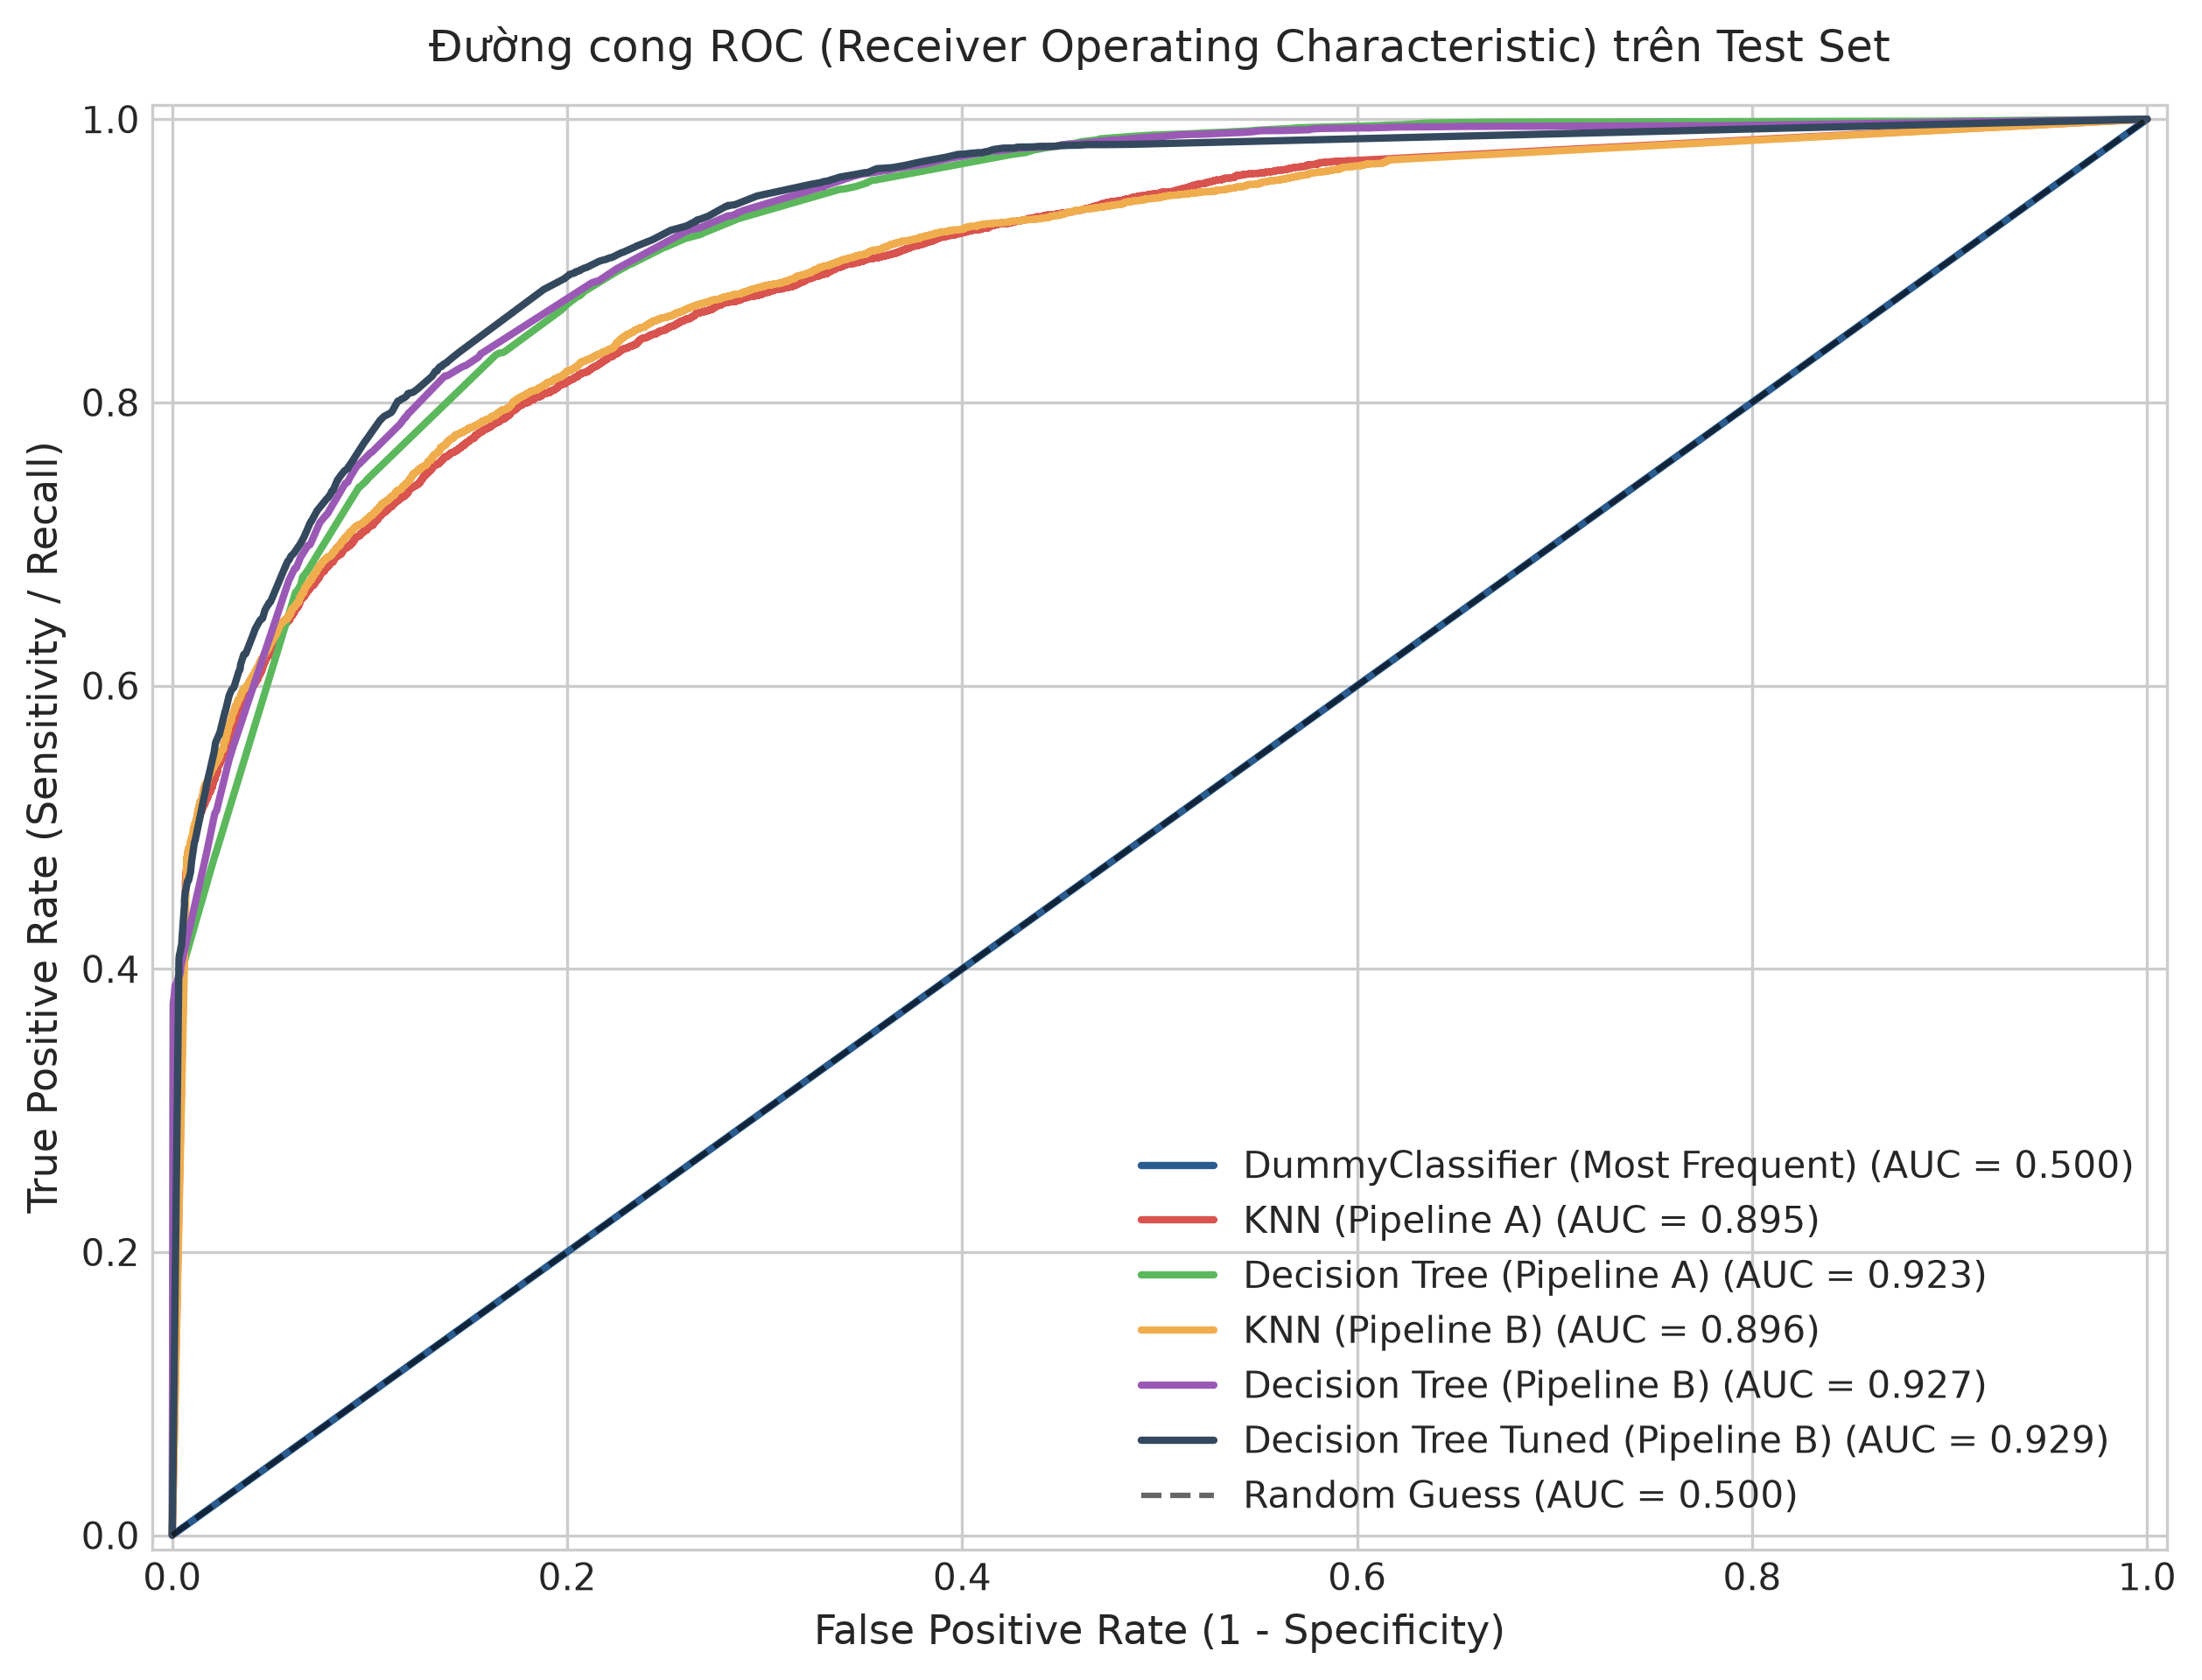

In [2]:
# Hiển thị biểu đồ ROC Curves
from IPython.display import Image, display
display(Image(filename=str(FIGURES_DIR / "roc_curves_comparison.png")))


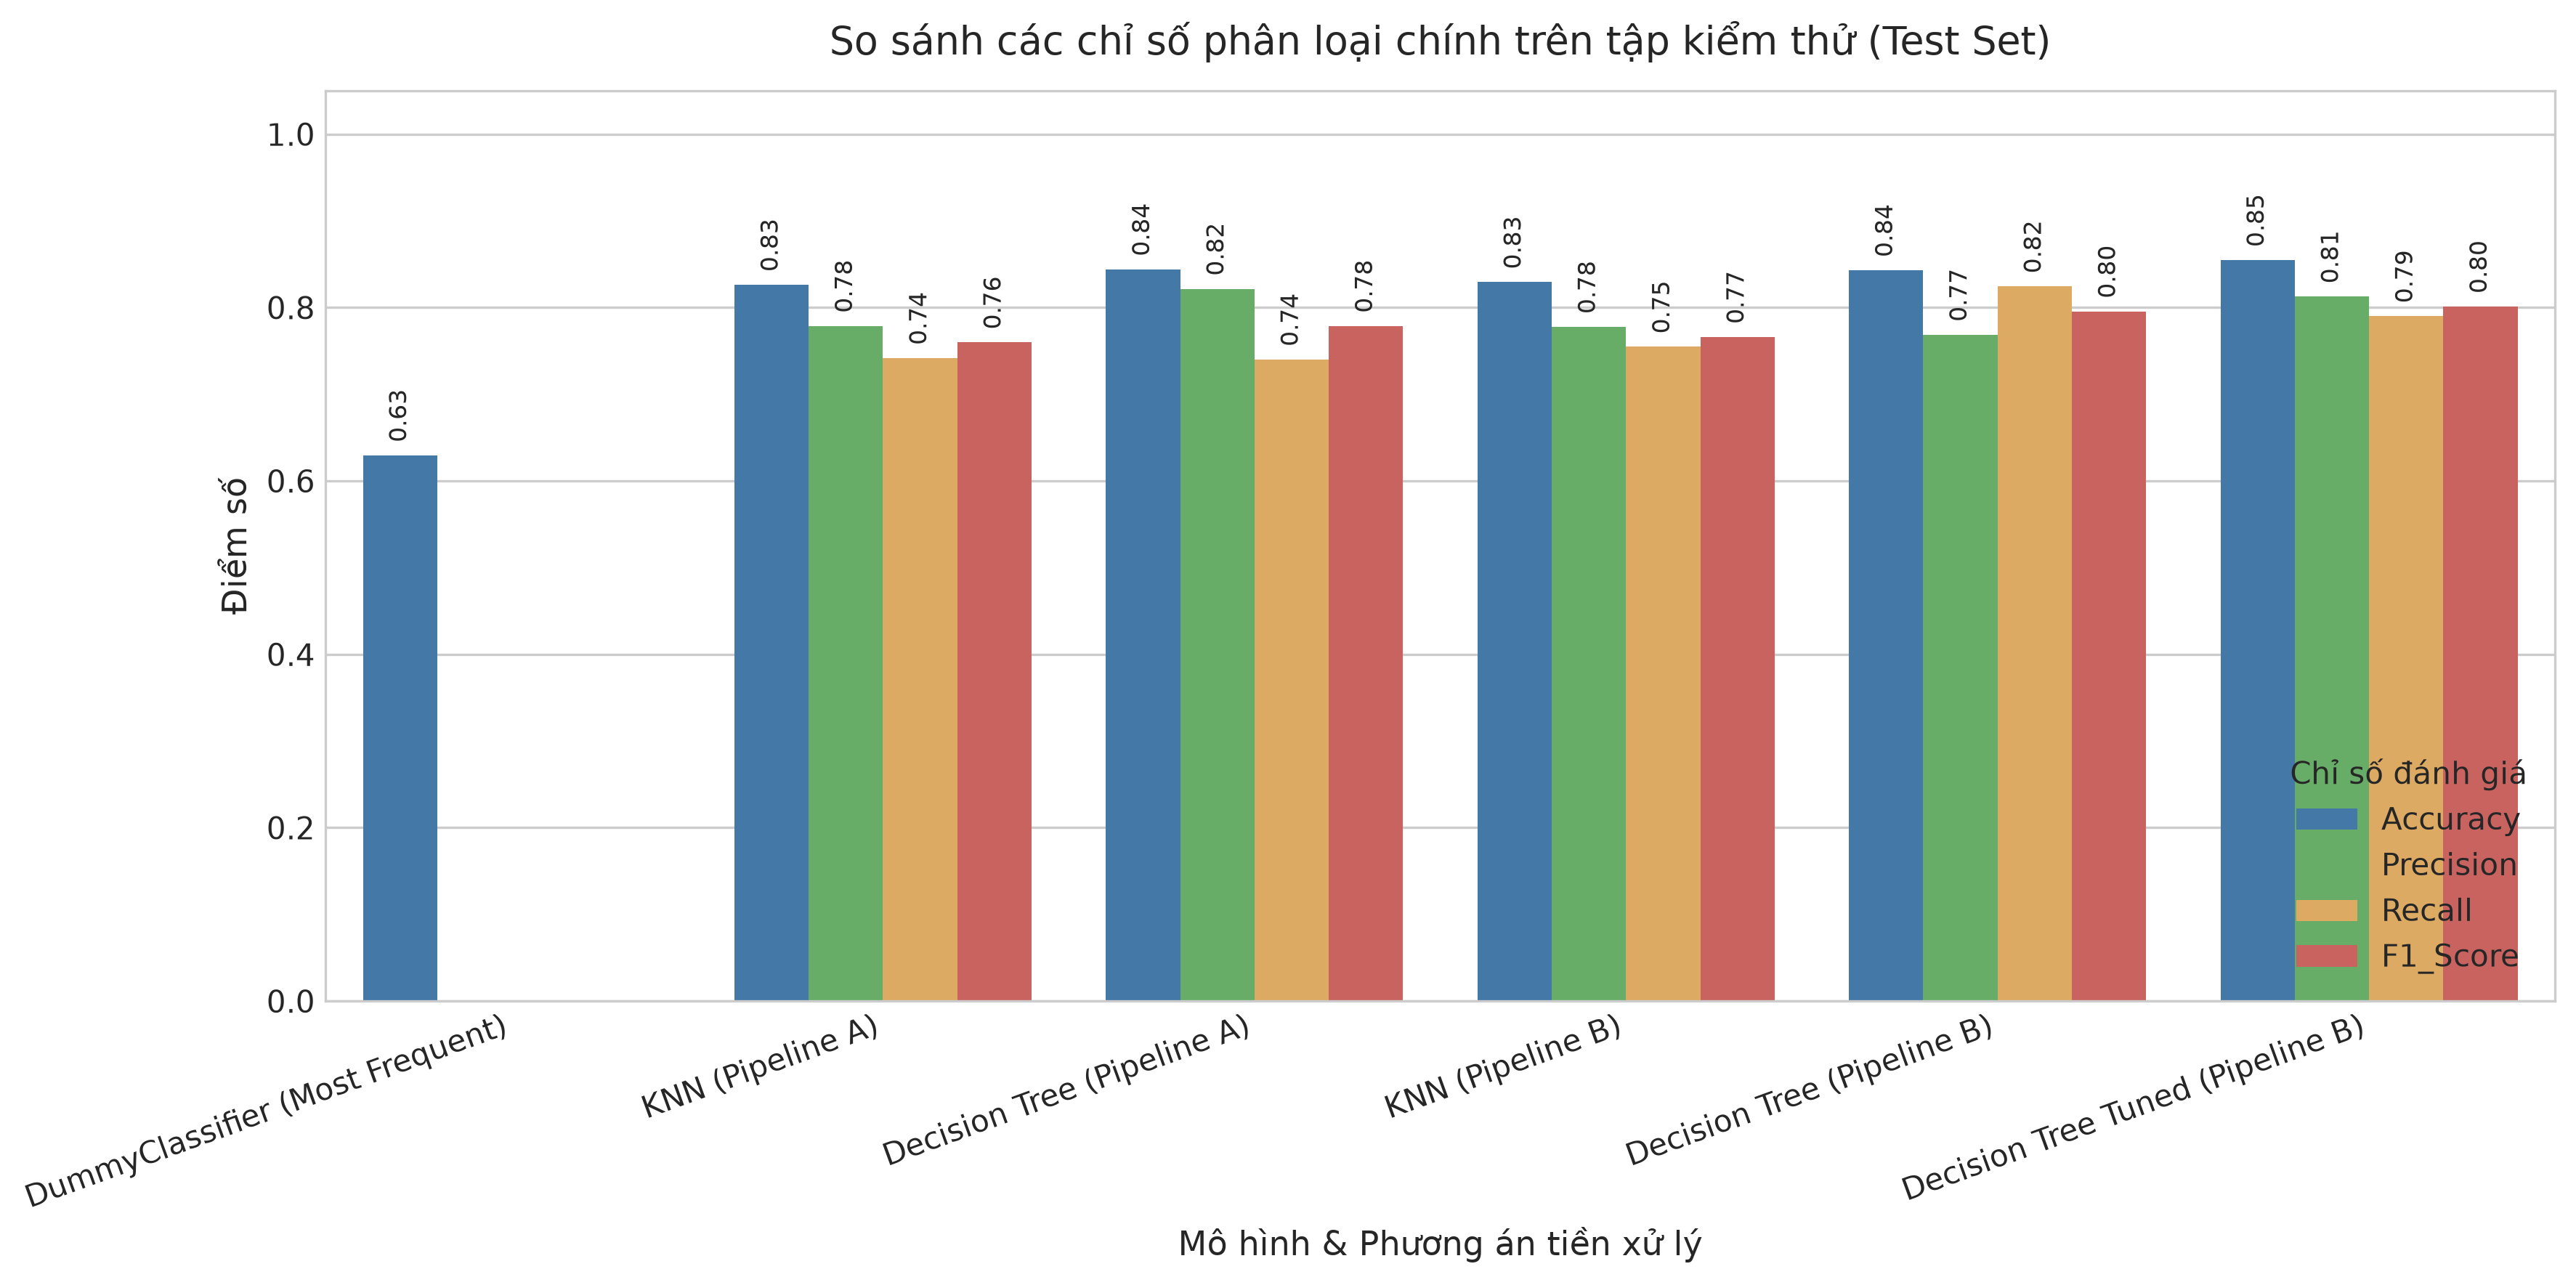

In [3]:
# Hiển thị biểu đồ so sánh Metric
display(Image(filename=str(FIGURES_DIR / "model_metrics_comparison.png")))


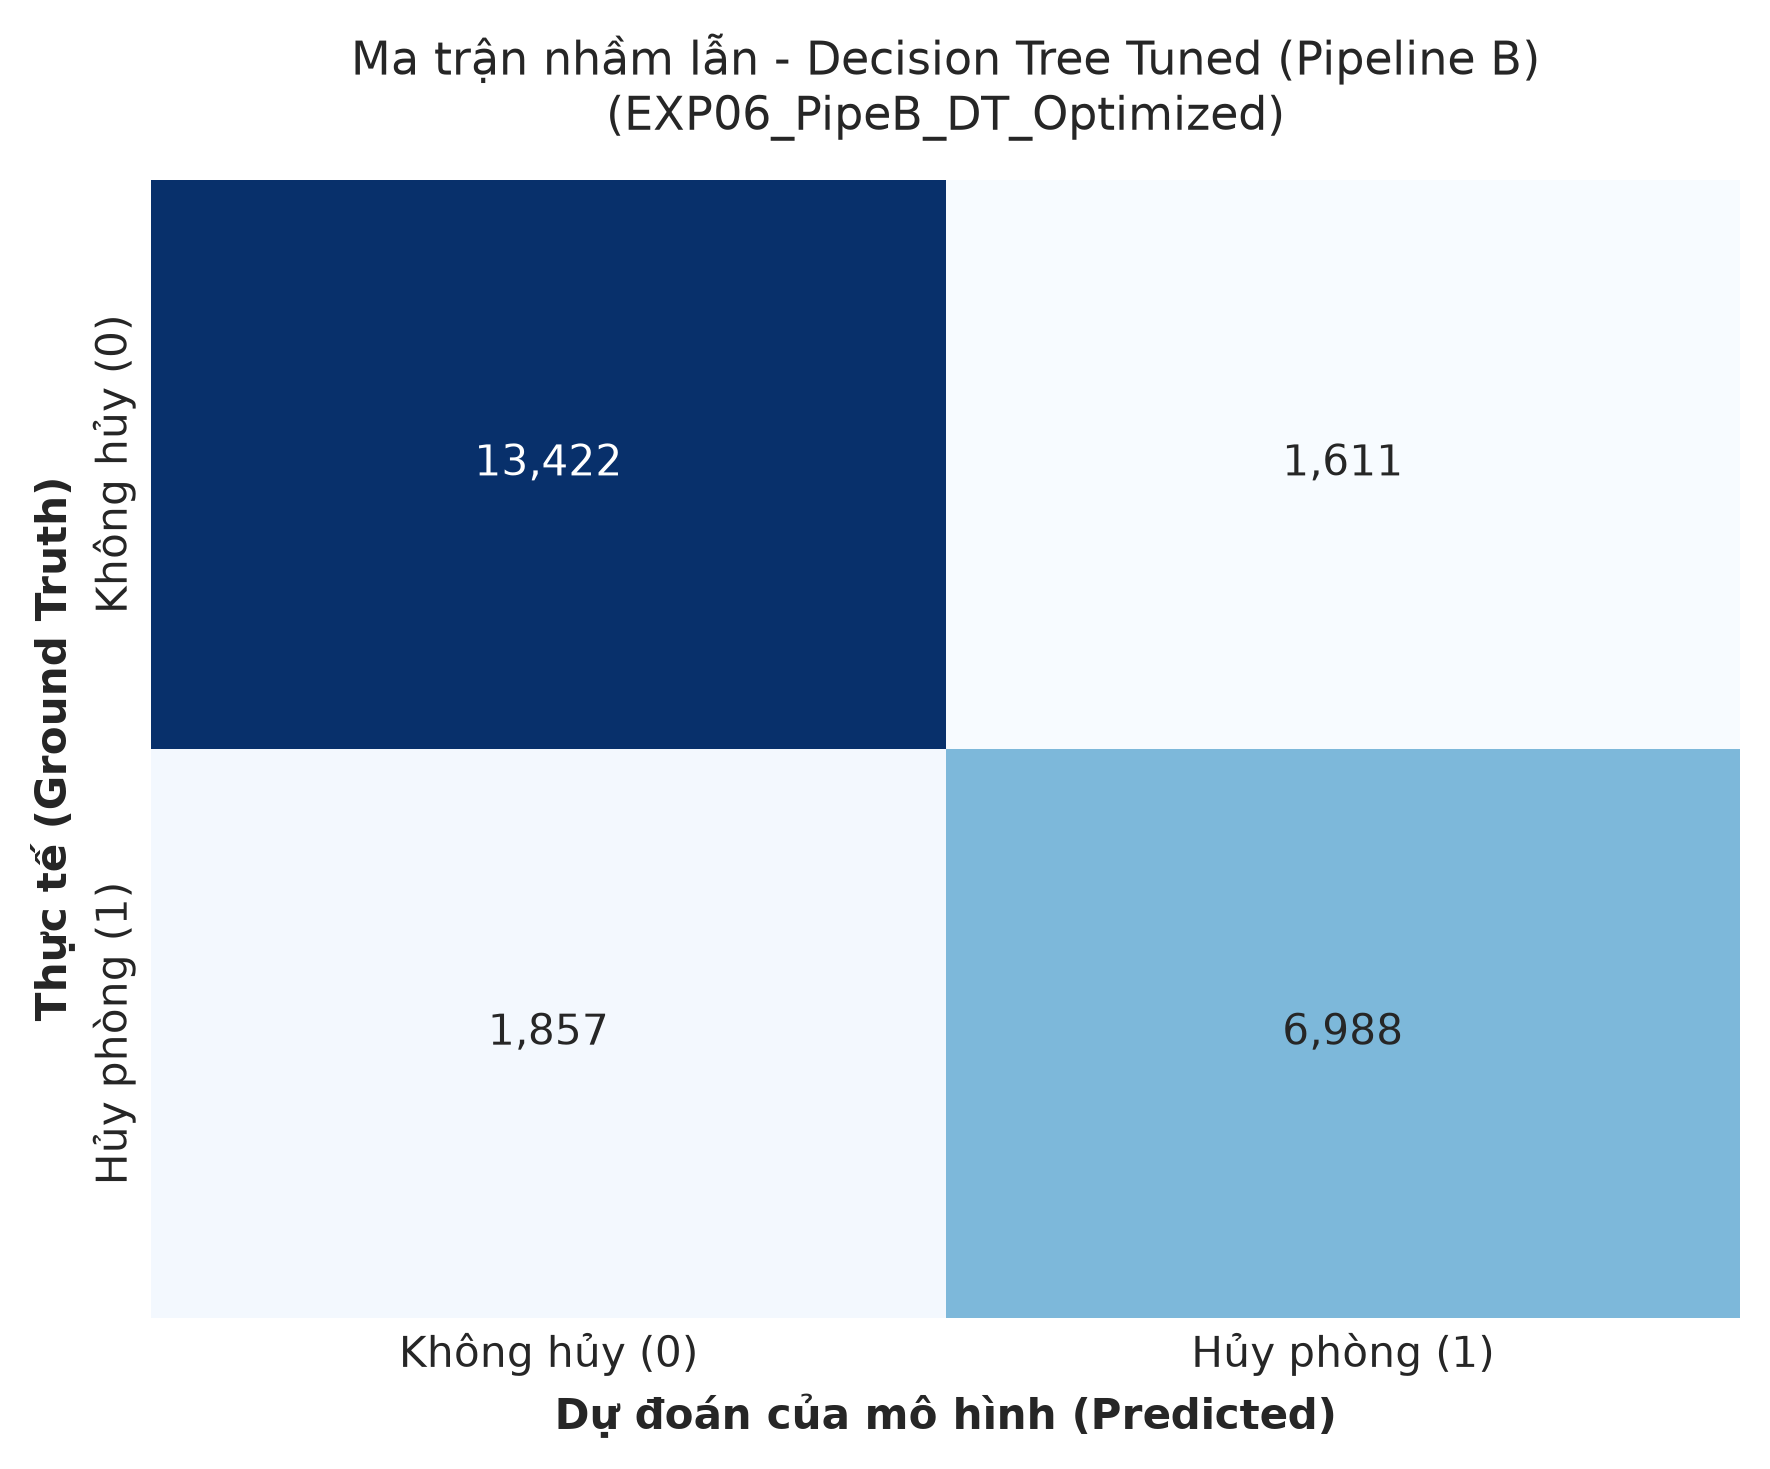

In [4]:
# Hiển thị Ma trận nhầm lẫn của mô hình tốt nhất (EXP06)
display(Image(filename=str(FIGURES_DIR / "confusion_matrix_exp06_pipeb_dt_optimized.png")))


## 2. Phân tích lỗi (Error Analysis Breakdown)

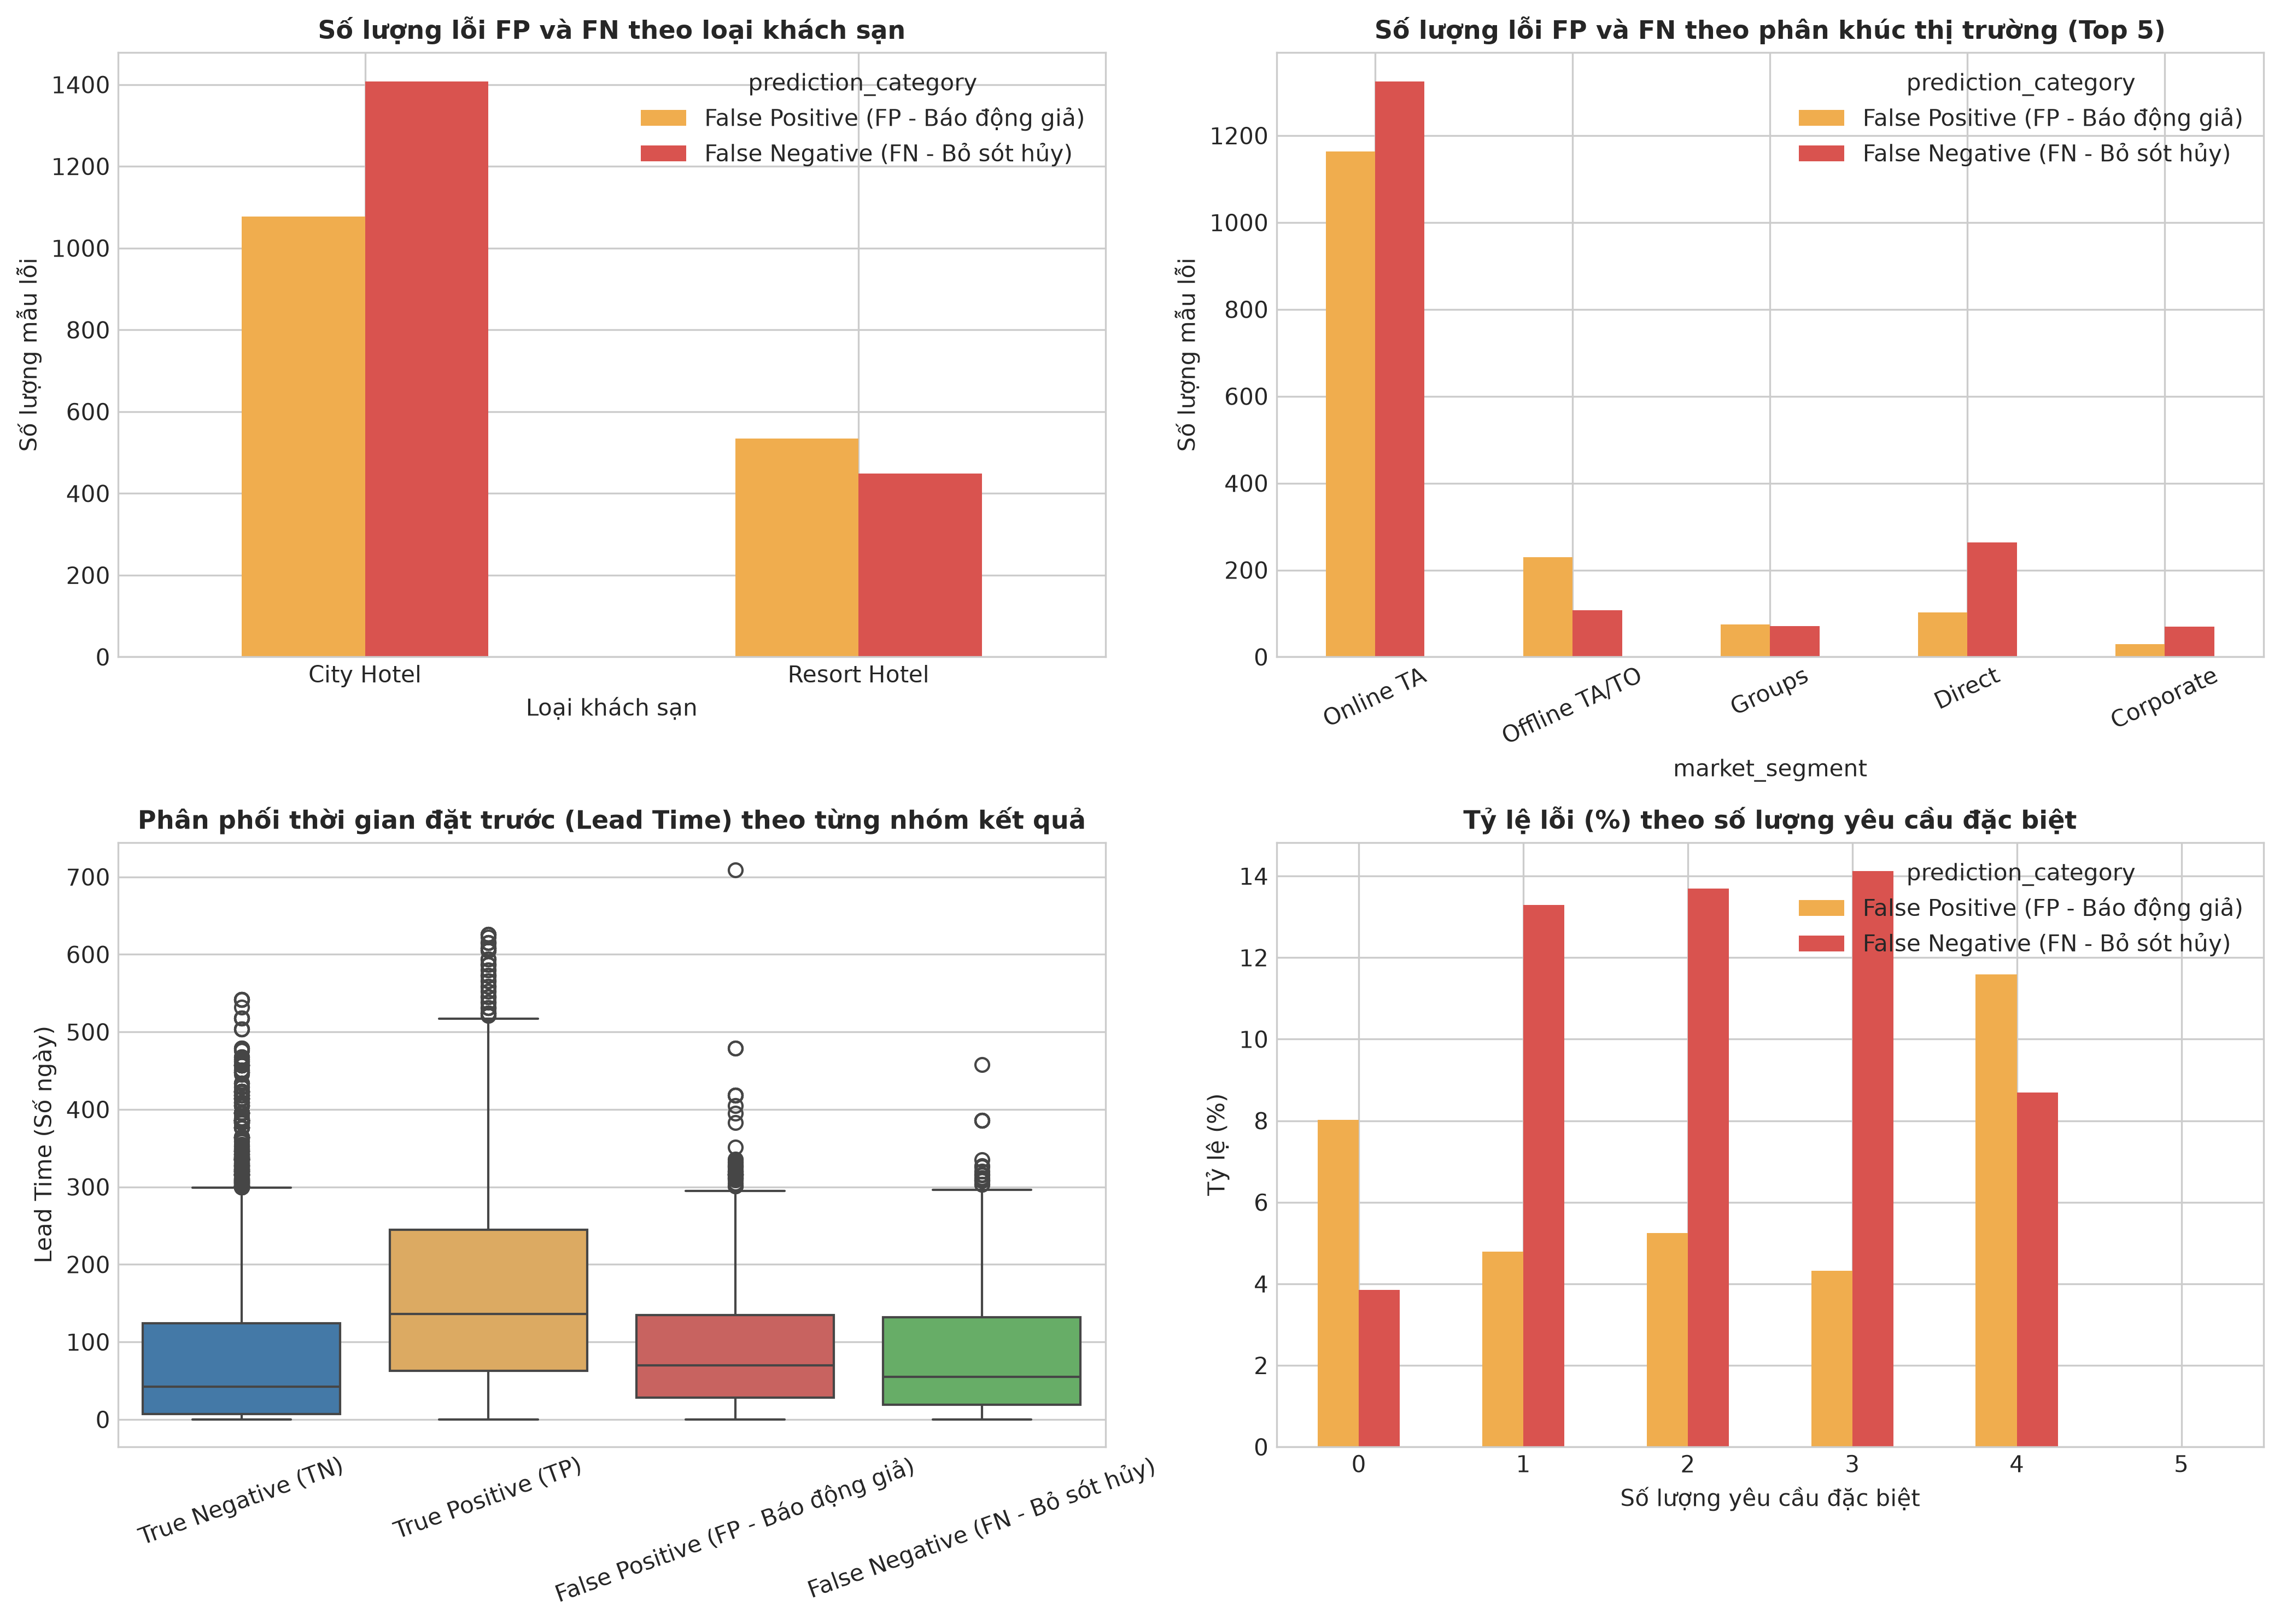

In [5]:
# Hiển thị đồ thị phân tích lỗi
display(Image(filename=str(FIGURES_DIR / "error_analysis_breakdown.png")))


### Kết luận Phân tích lỗi:
- **False Negative (Bỏ sót khách hủy):** Chiếm 7.78% tổng số mẫu test. Đặc điểm chính: thời gian đặt phòng ngắn (trung bình 83.4 ngày so với 161.9 ngày của nhóm bắt trúng), 75.8% xảy ra tại City Hotel.
- **False Positive (Báo động giả):** Chiếm 6.75% tổng số mẫu test. Khách đặt phòng từ trước nhưng không hủy. Khách sạn cần thận trọng khi áp dụng chính sách overbooking với nhóm này.
